# Simple LSTM Tutorial with PyTorch

## Forecasting synthetic daily temperature

This beginner tutorial uses an **LSTM** to predict tomorrow's temperature from the previous 30 days.

It will:

1. create synthetic temperature data;
2. prepare sequences;
3. explain the main LSTM components;
4. build and train a PyTorch model;
5. compare it with a persistence baseline.

The data use daily observations from 2019–2023 and random seed `42`.

Overall workflow: 30 daily temperatures → LSTM → next-day temperature.

In [ ]:
# @title
from IPython.display import HTML, display

mermaid_chart = r"""
<div class="mermaid">
flowchart LR
    A["30 daily temperatures<br/>(batch, 30, 1)"]
    B["LSTM model<br/>32 hidden units"]
    C["Next-day temperature<br/>(batch, 1)"]

    A --> B --> C

    classDef input fill:#EAF3FF,stroke:#2878D0,stroke-width:2px,color:#000;
    classDef model fill:#D6E9FF,stroke:#1769C2,stroke-width:2px,color:#000;
    classDef output fill:#E8F6EE,stroke:#2E8B57,stroke-width:2px,color:#000;

    class A input;
    class B model;
    class C output;
</div>

<script type="module">
import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.esm.min.mjs";

mermaid.initialize({
    startOnLoad: true,
    theme: "base",
    flowchart: {
        curve: "linear",
        htmlLabels: true,
        nodeSpacing: 45,
        rankSpacing: 50
    },
    themeVariables: {
        fontFamily: "Arial, sans-serif",
        fontSize: "17px",
        lineColor: "#222222"
    }
});

await mermaid.run({
    querySelector: ".mermaid"
});
</script>
"""

display(HTML(mermaid_chart))

## 1. Install packages

In [ ]:
# Run only if required.
# %pip install numpy pandas matplotlib scikit-learn torch

## 2. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


## 3. Create synthetic daily temperature data

In [ ]:
dates = pd.date_range("2019-01-01", "2023-12-31", freq="D")
t = np.arange(len(dates))

base_temperature = 18.0
annual_cycle = 8.0 * np.sin(2 * np.pi * t / 365.25 - np.pi / 2)
short_cycle = 1.2 * np.sin(2 * np.pi * t / 30)
warming_trend = 0.0008 * t
noise = np.random.normal(0.0, 1.4, len(dates))

temperature = (
    base_temperature + annual_cycle + short_cycle
    + warming_trend + noise
)

df = pd.DataFrame({
    "date": dates,
    "temperature_c": temperature
})

df.head()

,date,temperature_c
0,2019-01-01,10.695400
1,2019-01-02,10.057908
2,2019-01-03,11.401182
3,2019-01-04,12.850635
4,2019-01-05,10.586091


## 4. Plot the data

count    1826.000000
mean       18.793225
std         5.907363
min         5.717378
25%        13.488180
50%        18.751227
75%        24.161636
max        30.876892
Name: temperature_c, dtype: float64


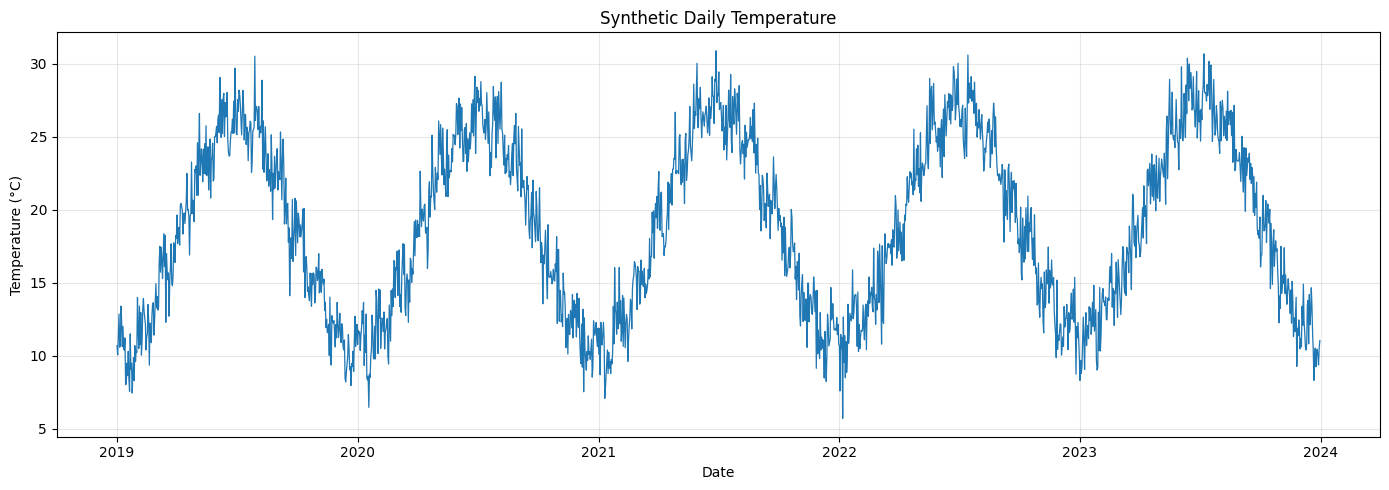

In [ ]:
print(df["temperature_c"].describe())

plt.figure(figsize=(14, 5))
plt.plot(df["date"], df["temperature_c"], linewidth=0.9)
plt.title("Synthetic Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Forecasting problem

Use the previous **30 days** to predict the next day:

$
[x_{t-29}, \ldots, x_t] \rightarrow x_{t+1}
$

PyTorch LSTM input shape:

`(batch size, sequence length, number of features)`

Here, sequence length = 30 and features = 1.

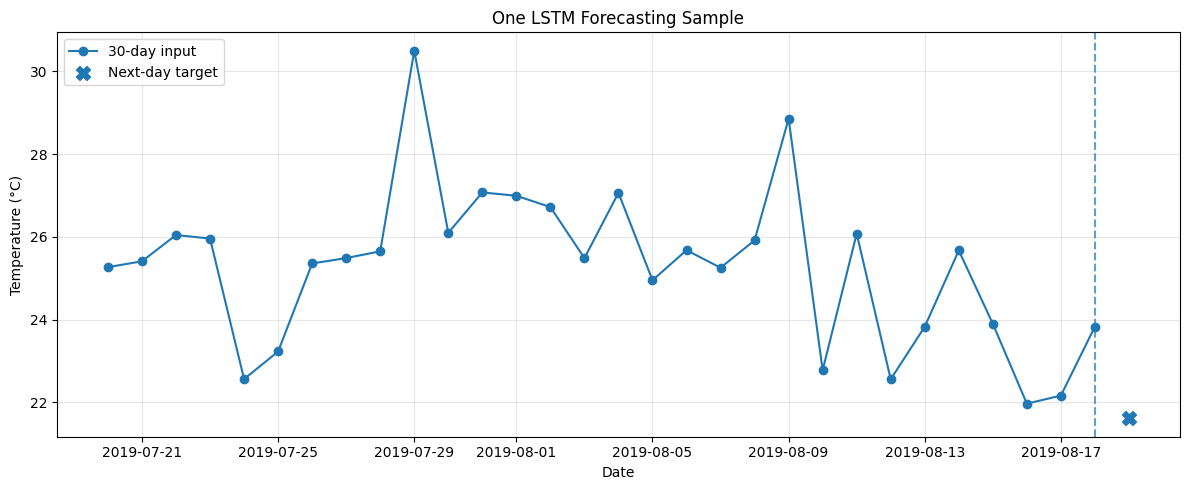


## 6. How an LSTM works

At time step $(t)$, the LSTM receives:

- current input $(x_t)$;
- previous hidden state $(h_{t-1})$;
- previous cell state $(c_{t-1})$.

It produces updated states $(h_t)$ and $(c_t)$.

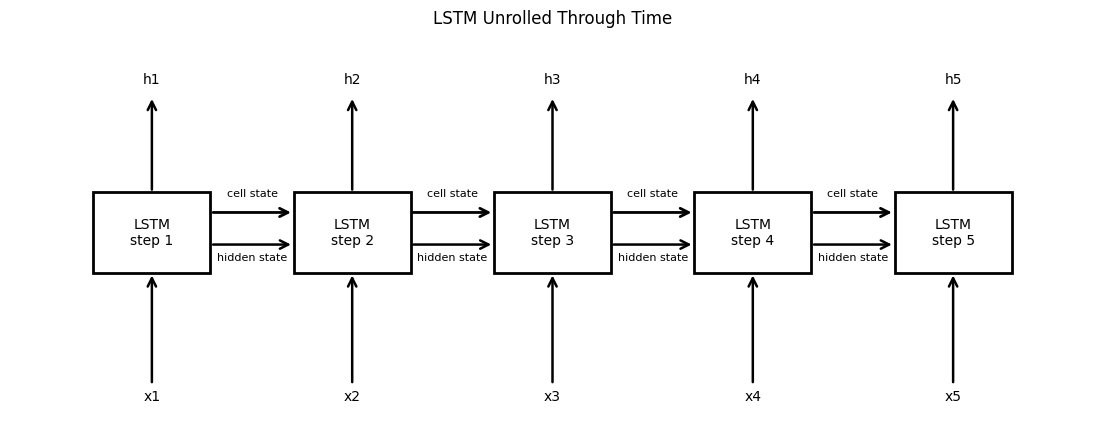

LSTM unrolled across several time steps, with inputs, hidden states and cell states.

## 7. Main components inside an LSTM cell

### 7.1 This is an LSTM cell

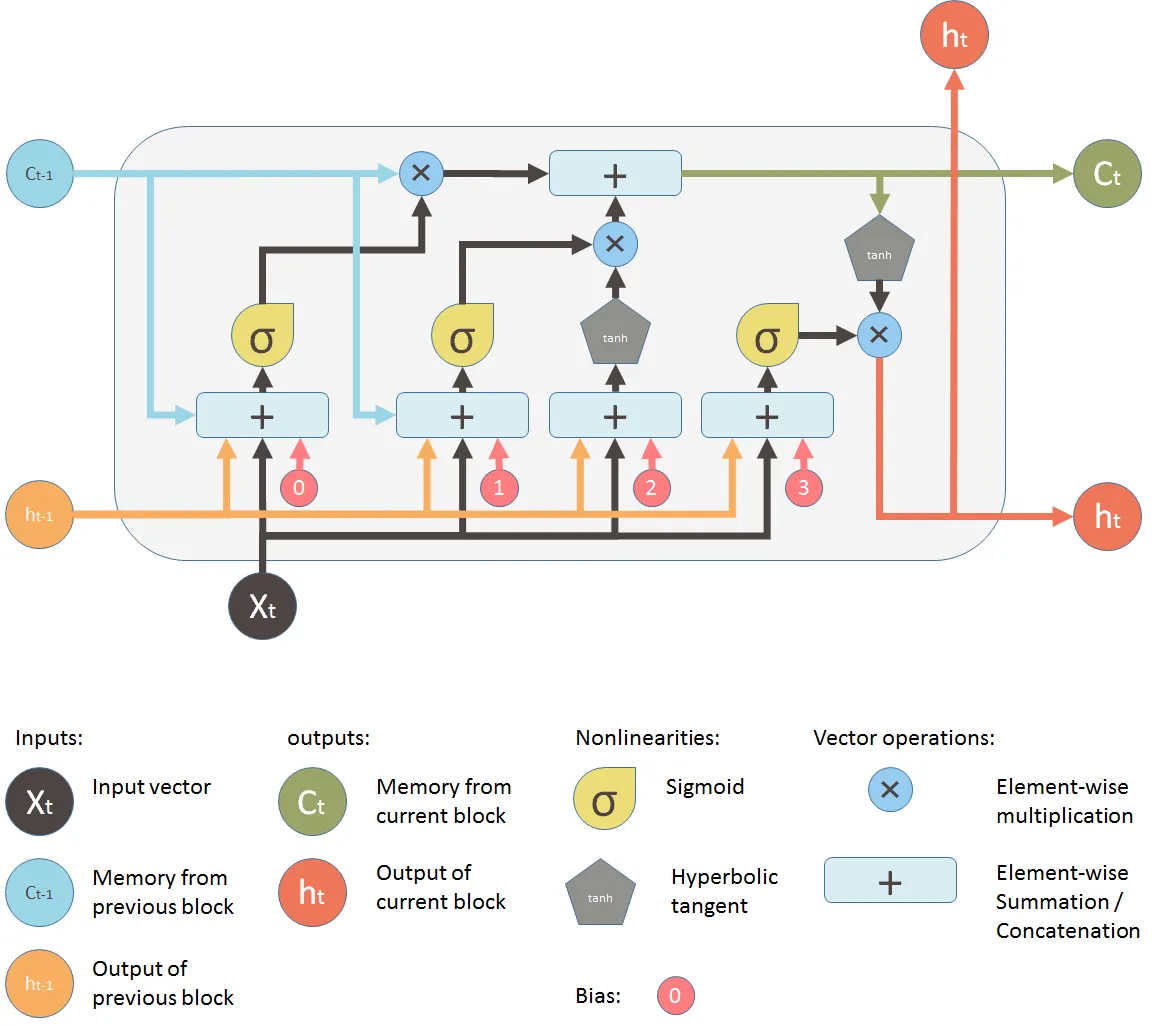

### 7.2 Forget gate
Controls how much old cell-state information is retained.

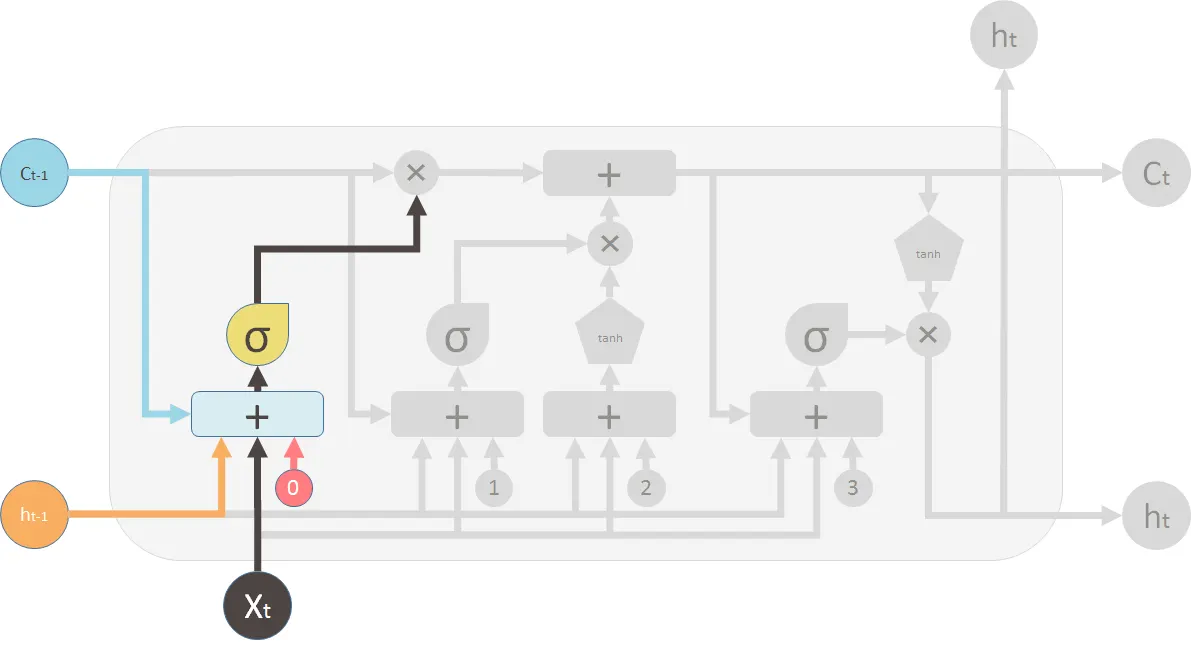

Forget-gate close-up showing $(x_t)$ and $(h_{t-1})$ entering a sigmoid gate and multiplying $(c_{t-1})$.

### 7.3 Input gate and candidate state
Control how much new information is written.
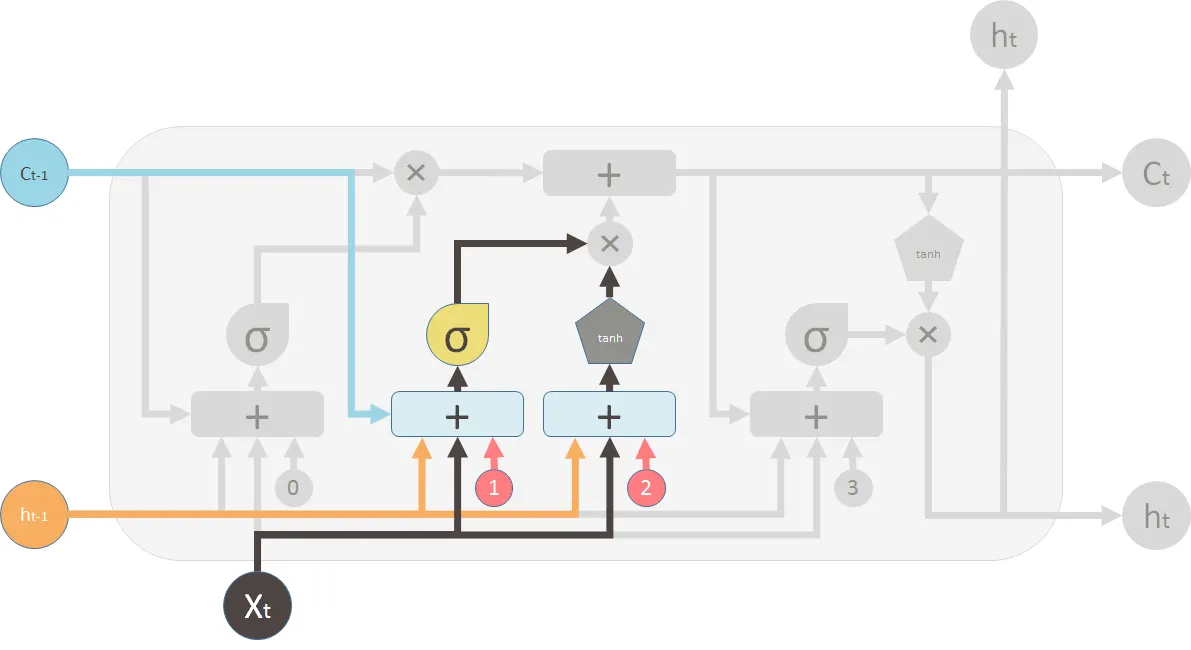

Input-gate and candidate-state close-up.

### 7.4 Cell-state update
Combines retained old information and selected new information.

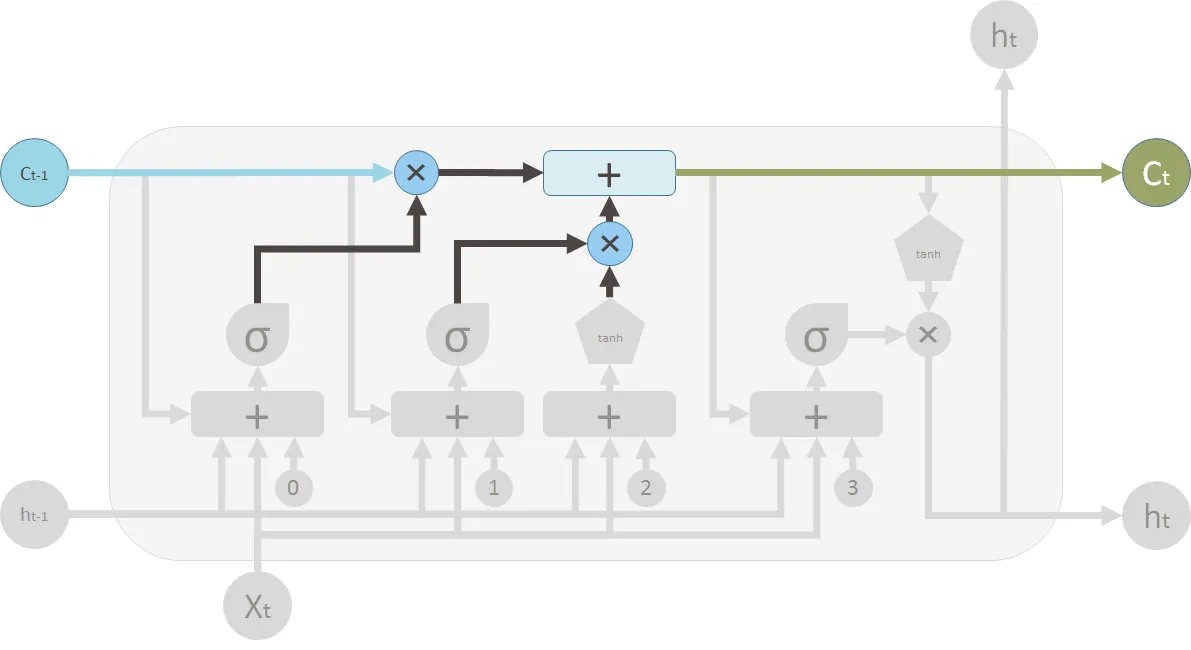
Cell-state update showing multiplication and addition operations.

### 7.5 Output gate
Controls how much updated cell-state information becomes the hidden output.

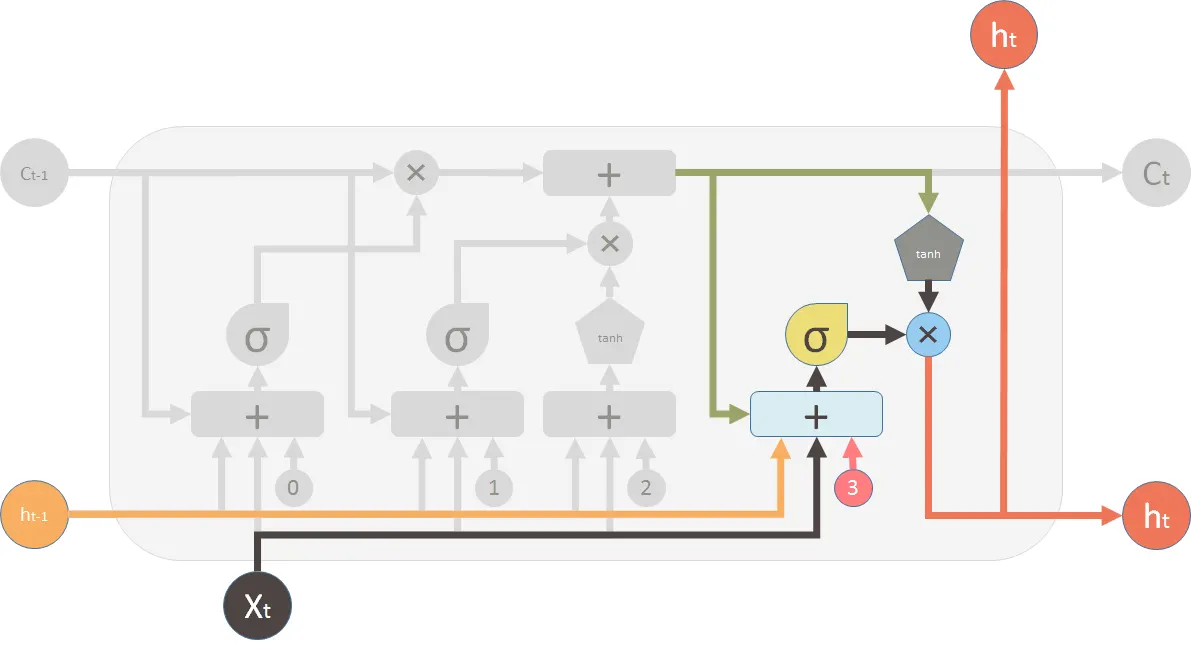
Output-gate close-up.

### 7.6 Complete LSTM-cell diagram showing all gates together:
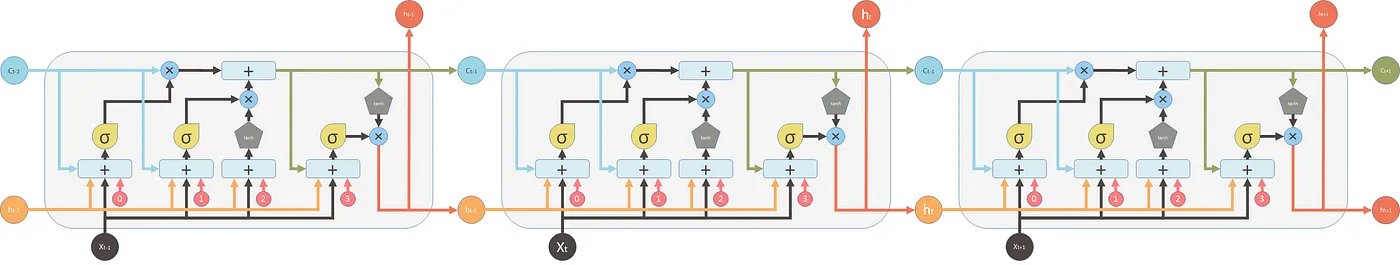

## 8. Split and scale the data
We use:

- 70% training;
- 15% validation;
- 15% testing.

The split is chronological to prevent future observations from leaking into the training period.

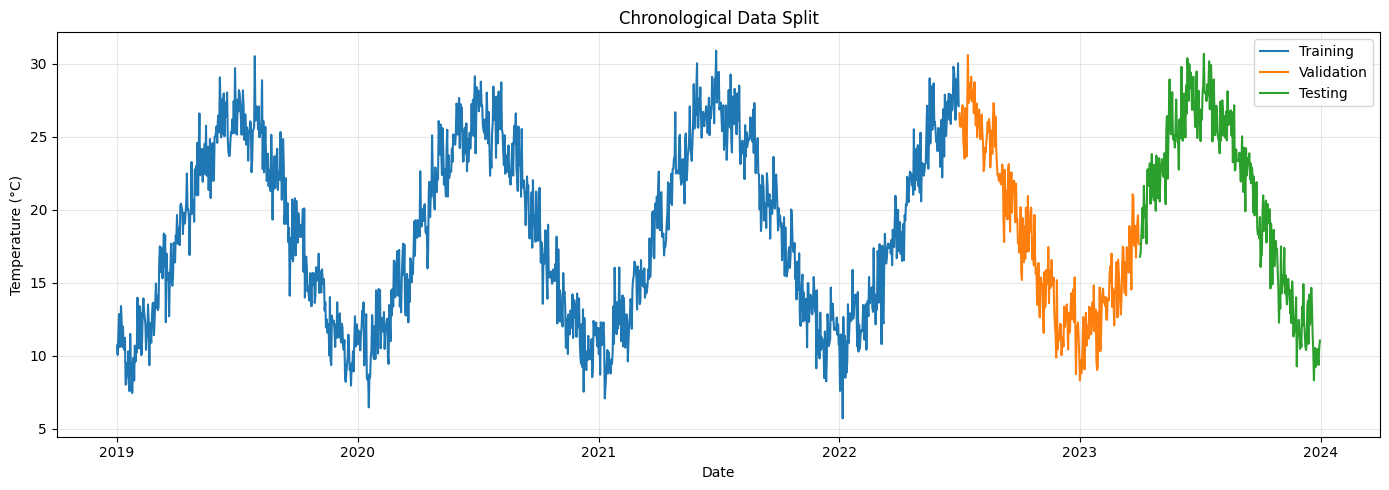


In [ ]:
values = df[["temperature_c"]].values

train_end = int(len(values) * 0.70)
validation_end = int(len(values) * 0.85)

train_values = values[:train_end]
validation_values = values[train_end:validation_end]
test_values = values[validation_end:]

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_values)

train_scaled = scaler.transform(train_values)
validation_scaled = scaler.transform(validation_values)
test_scaled = scaler.transform(test_values)

print(len(train_values), len(validation_values), len(test_values))

1278 274 274


## 9. Create 30-day sequences

In [ ]:
WINDOW_SIZE = 30

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, WINDOW_SIZE)

validation_with_history = np.concatenate([
    train_scaled[-WINDOW_SIZE:], validation_scaled
])
X_validation, y_validation = create_sequences(
    validation_with_history, WINDOW_SIZE
)

test_with_history = np.concatenate([
    validation_scaled[-WINDOW_SIZE:], test_scaled
])
X_test, y_test = create_sequences(
    test_with_history, WINDOW_SIZE
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (1248, 30, 1)
y_train: (1248, 1)


### X_train: (1248, 30, 1)

**1248**: This is the number of training samples or sequences. You have 1248 distinct 30-day sequences that the model will learn from.

**30**: This is your WINDOW_SIZE, meaning each input sequence consists of 30 consecutive days of temperature data.

**1**: This indicates that for each day in the sequence, there is 1 feature (in this case, 'temperature_c').

### y_train: (1248, 1)

**1248**: This is the number of target values, one for each of the 1248 input sequences in X_train.

**1**: This indicates that the model is predicting a single value for each sequence (the temperature of the next day).

### Example of 1 training sample:
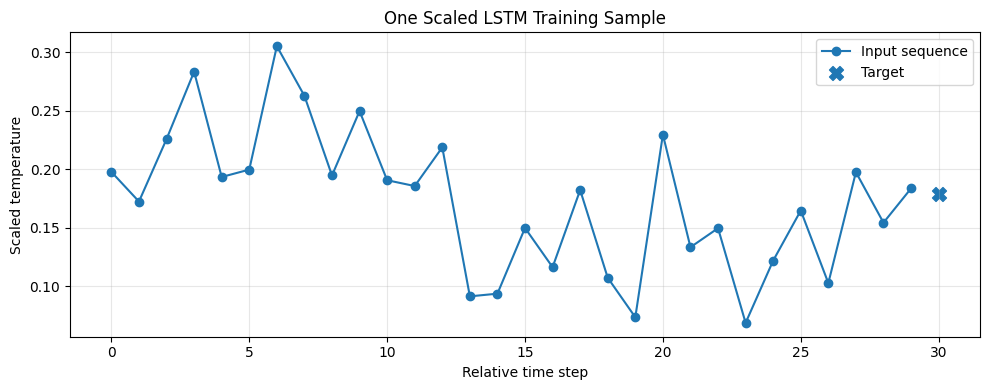

## 10. Convert data to PyTorch tensors and loaders

In [ ]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_validation_tensor = torch.tensor(X_validation, dtype=torch.float32)
y_validation_tensor = torch.tensor(y_validation, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=16, #model processes 16 training samples at once before updating its weights, you can use 8,16,32,64,128
    shuffle=False
)

validation_loader = DataLoader(
    TensorDataset(X_validation_tensor, y_validation_tensor),
    batch_size=16,
    shuffle=False
)

print(X_train_tensor.shape)

torch.Size([1248, 30, 1])


## 11. Build the PyTorch LSTM

The model contains:

- one LSTM layer with 32 hidden units;
- one linear output layer.

The final hidden output summarises the 30-day sequence.

### Model flow:
`(batch, 32, 1)` → LSTM(32) → final hidden output → linear layer → prediction.


In [ ]:
# @title
from IPython.display import HTML, display

mermaid_chart = r"""
<div class="mermaid">
flowchart LR
    A["Input sequence<br/>(batch, 30, 1)"]
    B["LSTM<br/>32 hidden units"]
    C["Final hidden output<br/>(batch, 32)"]
    D["Linear layer<br/>32 → 1"]
    E["Prediction<br/>(batch, 1)<br/>Next-day temperature"]

    A --> B --> C --> D --> E

    classDef input fill:#EAF3FF,stroke:#2878D0,stroke-width:2px,color:#000;
    classDef model fill:#D6E9FF,stroke:#1769C2,stroke-width:2px,color:#000;
    classDef hidden fill:#EAF3FF,stroke:#2878D0,stroke-width:2px,color:#000;
    classDef layer fill:#F2F2F2,stroke:#666666,stroke-width:2px,color:#000;
    classDef output fill:#D6E9FF,stroke:#1769C2,stroke-width:2px,color:#000;

    class A input;
    class B model;
    class C hidden;
    class D layer;
    class E output;
</div>

<script type="module">
import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.esm.min.mjs";

mermaid.initialize({
    startOnLoad: true,
    theme: "base",
    flowchart: {
        curve: "linear",
        htmlLabels: true,
        nodeSpacing: 35,
        rankSpacing: 45
    },
    themeVariables: {
        fontFamily: "Arial, sans-serif",
        fontSize: "16px",
        lineColor: "#222222"
    }
});

await mermaid.run({
    querySelector: ".mermaid"
});
</script>
"""

display(HTML(mermaid_chart))

In [ ]:
# @title
from IPython.display import HTML, display

mermaid_chart = r"""
<div class="mermaid">
flowchart TB

    A["Input batch<br/>
    16 samples<br/>
    Shape: (16, 30, 1)"]

    subgraph LSTMROW["LSTM processing across 30 days"]
        direction LR

        L1["Day 1<br/>
        LSTM cell<br/>
        h₁, c₁: (16, 32)"]

        L2["Day 2<br/>
        LSTM cell<br/>
        h₂, c₂: (16, 32)"]

        LD["..."]

        L30["Day 30<br/>
        LSTM cell<br/>
        h₃₀, c₃₀: (16, 32)"]

        L1 --> L2 --> LD --> L30
    end

    B["Final hidden output<br/>
    Shape: (16, 32)"]

    C["Linear layer<br/>
    32 → 1"]

    D["Next-day predictions<br/>
    Shape: (16, 1)"]

    A --> L1
    L30 --> B
    B --> C
    C --> D

    classDef input fill:#EAF3FF,stroke:#2878D0,stroke-width:2px,color:#000;
    classDef lstm fill:#D6E9FF,stroke:#1769C2,stroke-width:2px,color:#000;
    classDef hidden fill:#FFF4D6,stroke:#C58A00,stroke-width:2px,color:#000;
    classDef layer fill:#F1F1F1,stroke:#666666,stroke-width:2px,color:#000;
    classDef output fill:#E8F6EE,stroke:#2E8B57,stroke-width:2px,color:#000;

    class A input;
    class L1,L2,L30,LD lstm;
    class B hidden;
    class C layer;
    class D output;
</div>

<script type="module">
import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.esm.min.mjs";

mermaid.initialize({
    startOnLoad: true,
    theme: "base",
    flowchart: {
        curve: "linear",
        htmlLabels: true,
        nodeSpacing: 35,
        rankSpacing: 40
    },
    themeVariables: {
        fontFamily: "Arial, sans-serif",
        fontSize: "17px",
        lineColor: "#222222"
    }
});

await mermaid.run({
    querySelector: ".mermaid"
});
</script>
"""

display(HTML(mermaid_chart))

In [ ]:
class TemperatureLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=32): #LSTM produces a hidden representation containing 32 values for each sample. You can use 8,16,32,..
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, (hidden_state, cell_state) = self.lstm(x)
        final_output = sequence_output[:, -1, :]
        return self.output_layer(final_output)

model = TemperatureLSTM()
print(model)

TemperatureLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)


## 12. Inspect one forward pass

In [ ]:
example_X, example_y = next(iter(train_loader))
example_prediction = model(example_X)

print("Input:", example_X.shape)
print("Target:", example_y.shape)
print("Prediction:", example_prediction.shape)

Input: torch.Size([16, 30, 1])
Target: torch.Size([16, 1])
Prediction: torch.Size([16, 1])


## 13. Train the model

Each batch follows:

1. clear gradients;
2. forward pass;
3. calculate loss;
4. backpropagate;
5. update weights.

Training loop: forward pass → loss → backpropagation → optimiser step.

In [ ]:
# @title
from IPython.display import HTML, display

mermaid_chart = r"""
<div class="mermaid">
flowchart LR
    A["1. Clear gradients<br/>optimizer.zero_grad()"]
    B["2. Forward pass<br/>predictions = model(X_batch)"]
    C["3. Calculate loss<br/>loss = loss_function(predictions, y_batch)"]
    D["4. Backpropagation<br/>loss.backward()"]
    E["5. Update weights<br/>optimizer.step()"]

    A --> B --> C --> D --> E
    E -. "Next batch" .-> A

    classDef step fill:#EAF3FF,stroke:#2878D0,stroke-width:2px,color:#000;
    classDef final fill:#D6E9FF,stroke:#1769C2,stroke-width:2px,color:#000;

    class A,B,C,D step;
    class E final;
</div>

<script type="module">
import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.esm.min.mjs";

mermaid.initialize({
    startOnLoad: true,
    theme: "base",
    flowchart: {
        curve: "linear",
        htmlLabels: true,
        nodeSpacing: 35,
        rankSpacing: 45
    },
    themeVariables: {
        fontFamily: "Arial, sans-serif",
        fontSize: "16px",
        lineColor: "#222222"
    }
});

await mermaid.run({
    querySelector: ".mermaid"
});
</script>
"""

display(HTML(mermaid_chart))

In [ ]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 30
training_losses = []
validation_losses = []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_function(predictions, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    validation_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in validation_loader:
            predictions = model(X_batch)
            loss = loss_function(predictions, y_batch)
            validation_loss += loss.item()

    train_loss /= len(train_loader)
    validation_loss /= len(validation_loader)

    training_losses.append(train_loss)
    validation_losses.append(validation_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train: {train_loss:.5f} | "
        f"Validation: {validation_loss:.5f}"
    )

Epoch 01/30 | Train: 0.12054 | Validation: 0.02609
Epoch 02/30 | Train: 0.03282 | Validation: 0.01294
Epoch 03/30 | Train: 0.01586 | Validation: 0.00510
Epoch 04/30 | Train: 0.01072 | Validation: 0.00503
Epoch 05/30 | Train: 0.00917 | Validation: 0.00489
Epoch 06/30 | Train: 0.00837 | Validation: 0.00478
Epoch 07/30 | Train: 0.00776 | Validation: 0.00468
Epoch 08/30 | Train: 0.00729 | Validation: 0.00459
Epoch 09/30 | Train: 0.00691 | Validation: 0.00452
Epoch 10/30 | Train: 0.00660 | Validation: 0.00446
Epoch 11/30 | Train: 0.00635 | Validation: 0.00441
Epoch 12/30 | Train: 0.00615 | Validation: 0.00436
Epoch 13/30 | Train: 0.00597 | Validation: 0.00432
Epoch 14/30 | Train: 0.00582 | Validation: 0.00428
Epoch 15/30 | Train: 0.00570 | Validation: 0.00425
Epoch 16/30 | Train: 0.00559 | Validation: 0.00422
Epoch 17/30 | Train: 0.00549 | Validation: 0.00419
Epoch 18/30 | Train: 0.00541 | Validation: 0.00417
Epoch 19/30 | Train: 0.00534 | Validation: 0.00414
Epoch 20/30 | Train: 0.00527 | 

## 14. Plot training history

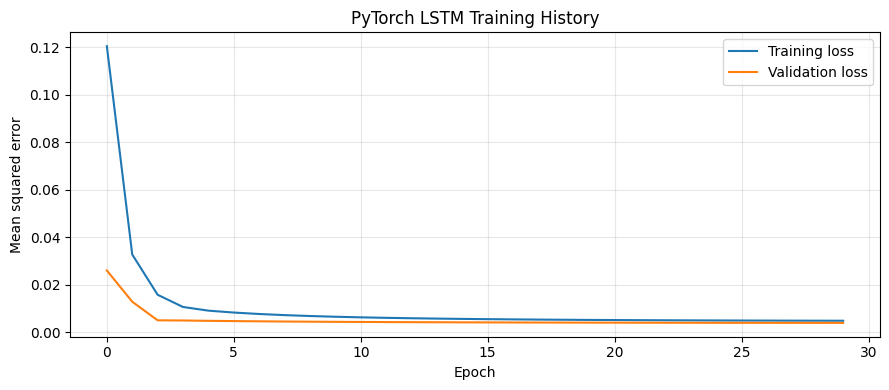

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(training_losses, label="Training loss")
plt.plot(validation_losses, label="Validation loss")
plt.title("PyTorch LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Baseline and LSTM evaluation

In [ ]:
actual_test_values = scaler.inverse_transform(y_test).flatten()

baseline_scaled = X_test[:, -1, 0].reshape(-1, 1)
baseline_predictions = scaler.inverse_transform(
    baseline_scaled
).flatten()

model.eval()
with torch.no_grad():
    predictions_scaled = model(X_test_tensor).numpy()

lstm_predictions = scaler.inverse_transform(
    predictions_scaled
).flatten()

baseline_mae = mean_absolute_error(
    actual_test_values, baseline_predictions
)
baseline_rmse = np.sqrt(mean_squared_error(
    actual_test_values, baseline_predictions
))

lstm_mae = mean_absolute_error(
    actual_test_values, lstm_predictions
)
lstm_rmse = np.sqrt(mean_squared_error(
    actual_test_values, lstm_predictions
))

results = pd.DataFrame({
    "Model": ["Persistence baseline", "PyTorch LSTM"],
    "MAE (°C)": [baseline_mae, lstm_mae],
    "RMSE (°C)": [baseline_rmse, lstm_rmse]
})

results.round(3)

,Model,MAE (°C),RMSE (°C)
0,Persistence baseline,1.592,1.944
1,PyTorch LSTM,1.239,1.585


## 16. Plot predictions

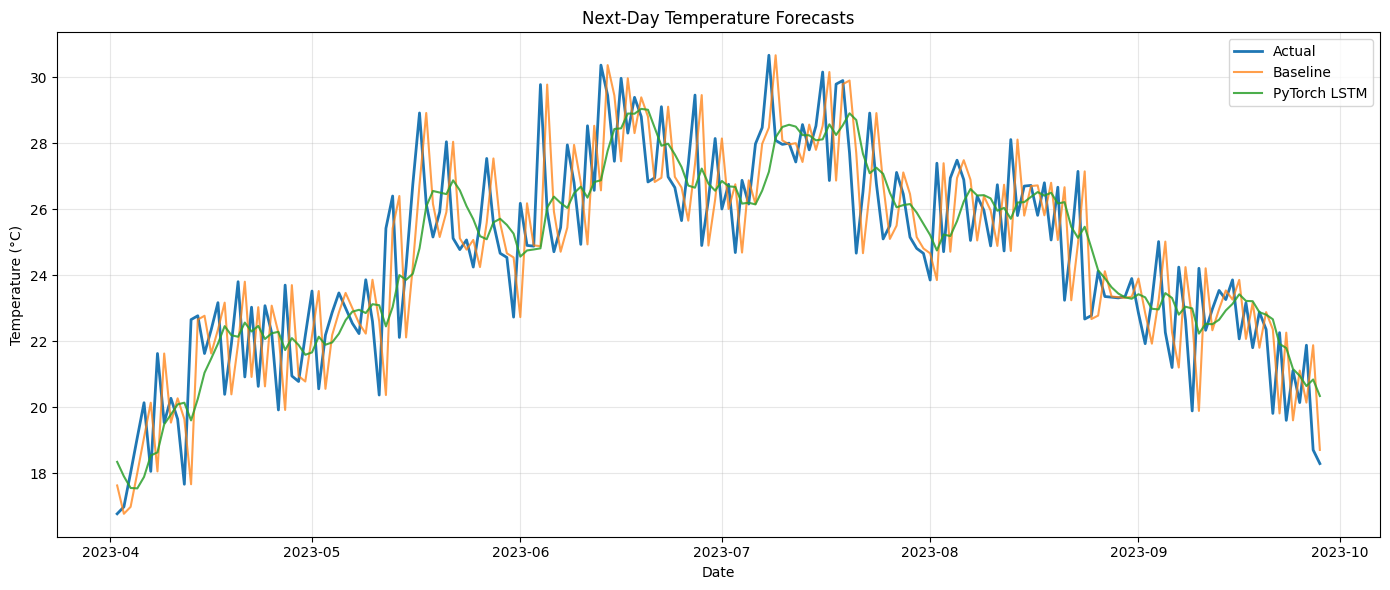

In [ ]:
test_dates = df["date"].iloc[validation_end:].reset_index(drop=True)
number_to_plot = 180

plt.figure(figsize=(14, 6))
plt.plot(
    test_dates.iloc[:number_to_plot],
    actual_test_values[:number_to_plot],
    label="Actual",
    linewidth=2
)
plt.plot(
    test_dates.iloc[:number_to_plot],
    baseline_predictions[:number_to_plot],
    label="Baseline",
    alpha=0.75
)
plt.plot(
    test_dates.iloc[:number_to_plot],
    lstm_predictions[:number_to_plot],
    label="PyTorch LSTM",
    alpha=0.85
)
plt.title("Next-Day Temperature Forecasts")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1 day example:
Actual next-day temperature:    25.12 °C

Predicted next-day temperature: 26.70 °C

Absolute error: 1.58 °C

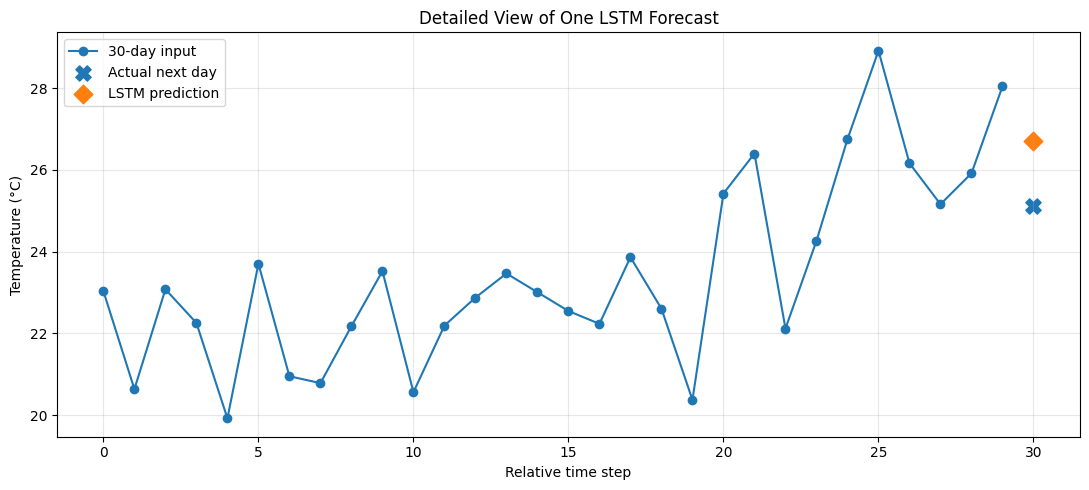



## 17. Summary

The PyTorch workflow is:

1. generate data;
2. split chronologically;
3. scale using training data;
4. create sequences;
5. convert to tensors;
6. create DataLoaders;
7. define an `nn.LSTM` model;
8. train with a manual loop;
9. evaluate against a baseline.

## 18. Suggested exercises

1. Change the hidden size from 32 to 16 or 64.
2. Change the window from 30 to 14 or 60 days.
3. Use `num_layers=2`.
4. Add dropout.
5. Predict seven days ahead.


## 19. References

- Visual LSTM: https://blog.mlreview.com/understanding-lstm-and-its-diagrams-37e2f46f1714
- PyTorch `nn.LSTM`: https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html
- PyTorch model-building tutorial: https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
- PyTorch optimisation tutorial: https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
- PyTorch data utilities: https://pytorch.org/docs/stable/data.html
- Hochreiter, S., & Schmidhuber, J. (1997). *Long short-term memory*. https://doi.org/10.1162/neco.1997.9.8.1735
- Christopher Olah, *Understanding LSTM Networks*: https://colah.github.io/posts/2015-08-Understanding-LSTMs/

# PART TWO: RECURSIVE FORECASTING

Only the first forecast uses 30 actual observations. Subsequent windows contain earlier predictions:

30 actual values → predict forecast day 1

29 actual values + forecast day 1 → predict forecast day 2

28 actual values + forecast days 1–2 → predict forecast day 3

In [ ]:
def recursive_forecast(
    model,
    initial_window,
    forecast_steps,
    scaler
):
    """
    Generate a recursive multi-step forecast.

    Parameters
    ----------
    model : torch.nn.Module
        Trained PyTorch LSTM model.

    initial_window : NumPy array
        The final observed input window.
        Expected shape: (window_size, 1).

    forecast_steps : int
        Number of future days to predict.

    scaler : fitted MinMaxScaler
        Used to convert predictions back to degrees Celsius.

    Returns
    -------
    predictions_c : NumPy array
        Recursive forecasts in degrees Celsius.
    """

    # Put the model in evaluation mode.
    model.eval()

    # Copy the initial window so the original data are unchanged.
    current_window = initial_window.copy()

    # Store scaled predictions.
    recursive_predictions_scaled = []

    with torch.no_grad():

        for step in range(forecast_steps):

            # Convert the current window to a PyTorch tensor.
            # Shape: (1 sample, 30 time steps, 1 feature)
            input_tensor = torch.tensor(
                current_window,
                dtype=torch.float32
            ).unsqueeze(0)

            # Predict the next scaled temperature.
            next_prediction = model(input_tensor)

            # Extract the numeric prediction.
            next_value = next_prediction.item()

            # Store it.
            recursive_predictions_scaled.append(next_value)

            # Remove the oldest value from the input window.
            current_window = current_window[1:]

            # Add the new prediction to the end of the window.
            current_window = np.vstack([
                current_window,
                [[next_value]]
            ])

    # Convert predictions into a two-dimensional array.
    recursive_predictions_scaled = np.array(
        recursive_predictions_scaled
    ).reshape(-1, 1)

    # Convert from scaled values back to degrees Celsius.
    predictions_c = scaler.inverse_transform(
        recursive_predictions_scaled
    ).flatten()

    return predictions_c

In [ ]:
# Use the final 30 scaled observations immediately before the test period.
initial_window = np.concatenate([
    train_scaled,
    validation_scaled
])[-WINDOW_SIZE:]

# Forecast the same number of days as the test period.
forecast_steps = len(test_values)

recursive_predictions = recursive_forecast(
    model=model,
    initial_window=initial_window,
    forecast_steps=forecast_steps,
    scaler=scaler
)

print("Number of recursive predictions:", len(recursive_predictions))

Number of recursive predictions: 274


In [ ]:
recursive_mae = mean_absolute_error(
    actual_test_values,
    recursive_predictions
)

recursive_rmse = np.sqrt(
    mean_squared_error(
        actual_test_values,
        recursive_predictions
    )
)

print(f"Recursive MAE:  {recursive_mae:.3f} °C")
print(f"Recursive RMSE: {recursive_rmse:.3f} °C")

Recursive MAE:  6.575 °C
Recursive RMSE: 7.927 °C


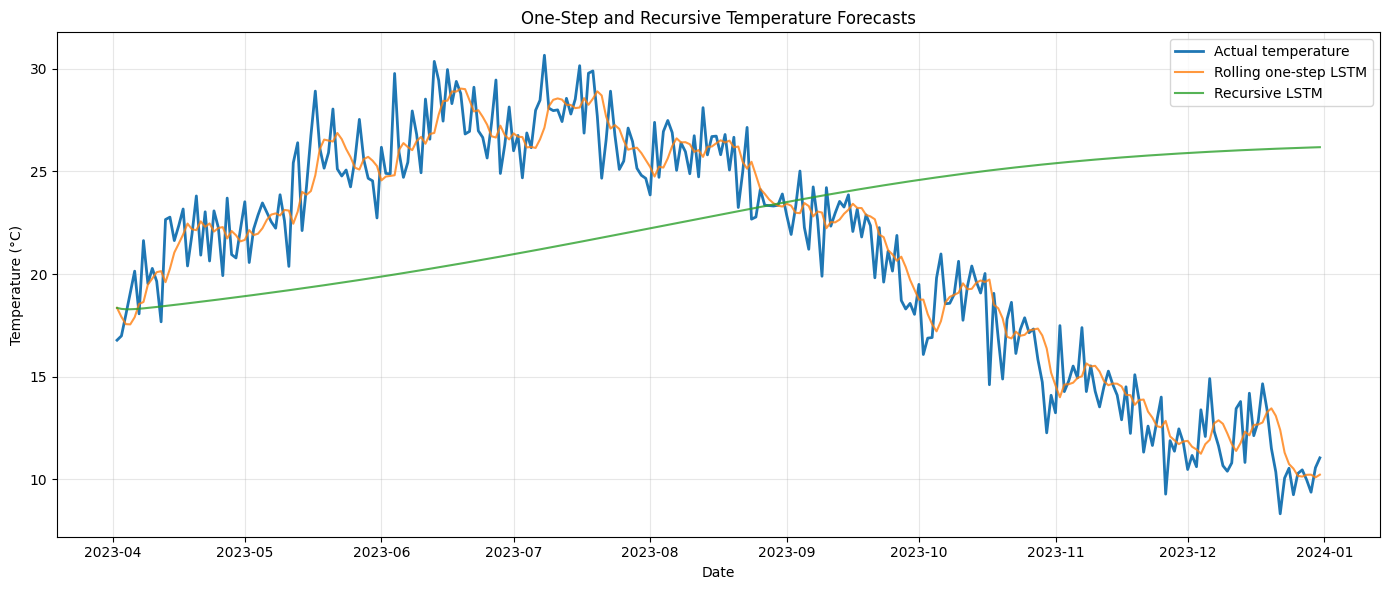

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual_test_values,
    label="Actual temperature",
    linewidth=2
)

plt.plot(
    test_dates,
    lstm_predictions,
    label="Rolling one-step LSTM",
    alpha=0.8
)

plt.plot(
    test_dates,
    recursive_predictions,
    label="Recursive LSTM",
    alpha=0.8
)

plt.title("One-Step and Recursive Temperature Forecasts")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

For an eight-month horizon, recursive errors will likely accumulate substantially.

# PART THREE: RECURSIVE FORECASTING WITH DAY-CYCLE INFORMATION

The recursive model in Part Two receives only previous temperatures. If its predictions drift, it has no independent information telling it where the forecast lies within the year.

Part Three uses three input features:

1. scaled temperature;
2. sine of day of year;
3. cosine of day of year.

For day \(d\):

$
\text{day_sin}=\sin\left(\frac{2\pi d}{365.25}\right), \qquad
\text{day_cos}=\cos\left(\frac{2\pi d}{365.25}\right)
$

The sine-cosine pair represents the annual cycle without an artificial jump between 31 December and 1 January. During recursive forecasting, only temperature is predicted; future calendar features are known and added directly.

## 20. Add cyclical day-of-year features

A raw day number from 1 to 365 is not ideal because day 365 and day 1 are adjacent in time. Sine and cosine preserve this circular relationship.

In [ ]:
# Keep the earlier tutorial data unchanged.
df_cycle = df.copy()

day_of_year = df_cycle["date"].dt.dayofyear

df_cycle["day_sin"] = np.sin(
    2 * np.pi * day_of_year / 365.25
)
df_cycle["day_cos"] = np.cos(
    2 * np.pi * day_of_year / 365.25
)

df_cycle[["date", "temperature_c", "day_sin", "day_cos"]].head()

,date,temperature_c,day_sin,day_cos
0,2019-01-01,10.695400,0.017202,0.999852
1,2019-01-02,10.057908,0.034398,0.999408
2,2019-01-03,11.401182,0.051584,0.998669
3,2019-01-04,12.850635,0.068755,0.997634
4,2019-01-05,10.586091,0.085906,0.996303


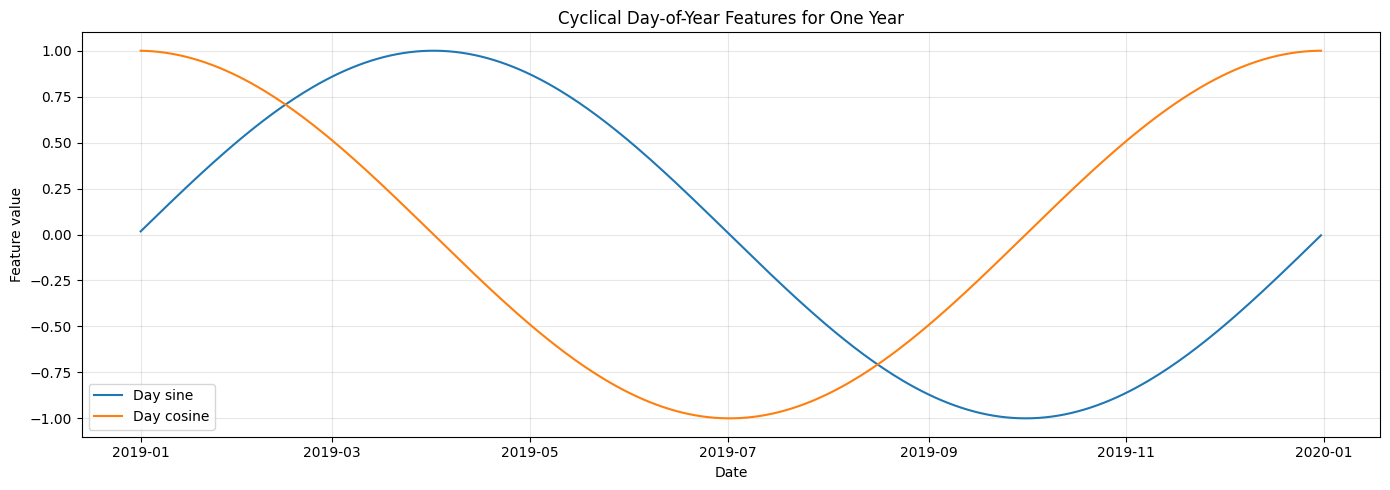

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(
    df_cycle["date"].iloc[:365],
    df_cycle["day_sin"].iloc[:365],
    label="Day sine"
)
plt.plot(
    df_cycle["date"].iloc[:365],
    df_cycle["day_cos"].iloc[:365],
    label="Day cosine"
)
plt.title("Cyclical Day-of-Year Features for One Year")
plt.xlabel("Date")
plt.ylabel("Feature value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 21. Scale temperature and assemble the input features

Only temperature is scaled with `MinMaxScaler`. The sine and cosine values are already bounded between -1 and 1.

Feature order:

```text
[scaled_temperature, day_sin, day_cos]
```

In [ ]:
temperature_values = df_cycle[["temperature_c"]].values

cycle_temperature_scaler = MinMaxScaler(feature_range=(0, 1))
cycle_temperature_scaler.fit(
    temperature_values[:train_end]
)

temperature_scaled_all = cycle_temperature_scaler.transform(
    temperature_values
).flatten()

cycle_features_all = np.column_stack([
    temperature_scaled_all,
    df_cycle["day_sin"].values,
    df_cycle["day_cos"].values
])

cycle_train_features = cycle_features_all[:train_end]
cycle_validation_features = cycle_features_all[train_end:validation_end]
cycle_test_features = cycle_features_all[validation_end:]

print("All features:", cycle_features_all.shape)
print("Training features:", cycle_train_features.shape)
print("Feature order: scaled temperature, day sine, day cosine")

All features: (1826, 3)
Training features: (1278, 3)
Feature order: scaled temperature, day sine, day cosine


## 22. Create multivariable sequences

The input shape is now:

```text
(samples, 30 days, 3 features)
```

The target remains only the next day's scaled temperature.

In [ ]:
def create_multivariable_sequences(
    feature_data,
    window_size,
    target_column=0
):
    X, y = [], []

    for i in range(len(feature_data) - window_size):
        X.append(feature_data[i:i + window_size])
        y.append(feature_data[i + window_size, target_column])

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32).reshape(-1, 1)
    )


X_train_cycle, y_train_cycle = create_multivariable_sequences(
    cycle_train_features,
    WINDOW_SIZE
)

validation_cycle_with_history = np.concatenate([
    cycle_train_features[-WINDOW_SIZE:],
    cycle_validation_features
])

X_validation_cycle, y_validation_cycle = create_multivariable_sequences(
    validation_cycle_with_history,
    WINDOW_SIZE
)

test_cycle_with_history = np.concatenate([
    cycle_validation_features[-WINDOW_SIZE:],
    cycle_test_features
])

X_test_cycle, y_test_cycle = create_multivariable_sequences(
    test_cycle_with_history,
    WINDOW_SIZE
)

print("X_train_cycle:", X_train_cycle.shape)
print("y_train_cycle:", y_train_cycle.shape)
print("X_test_cycle:", X_test_cycle.shape)

X_train_cycle: (1248, 30, 3)
y_train_cycle: (1248, 1)
X_test_cycle: (274, 30, 3)


## 23. Build and train a three-input LSTM

The architecture is similar to Part One, but `input_size=3`.

In [ ]:
# @title
from IPython.display import HTML, display

mermaid_code = """
flowchart LR
    T["Temperature"] --> A["Input sequence<br/>30 days × 3 features"]
    S["Day-of-year sine"] --> A
    C["Day-of-year cosine"] --> A

    A --> B["LSTM layer<br/>input_size = 3"]
    B --> D["Final hidden state"]
    D --> E["Linear layer<br/>1 output"]
    E --> F["Next-day temperature prediction"]

    F -. "Predicted temperature<br/>used in next sequence" .-> A
    G["Known future date"] --> H["Calculate future<br/>sine and cosine"]
    H -.-> A
"""

display(HTML(f"""
<div class="mermaid">
{mermaid_code}
</div>

<script type="module">
import mermaid from 'https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.esm.min.mjs';
mermaid.initialize({{
    startOnLoad: true,
    theme: 'default'
}});
await mermaid.run();
</script>
"""))

In [ ]:
# @title
from IPython.display import HTML, display

mermaid_code = """
flowchart TB

    A["Input batch<br/><br/>16 samples<br/><br/>Shape: (16, 30, 3)"]

    subgraph S["LSTM processing across 30 days"]
        direction LR

        D1["Day 1<br/><br/>3 input features<br/><br/>Temperature<br/>Day sine<br/>Day cosine"]
        L1["LSTM cell<br/><br/>h₁, c₁: (16, 32)"]

        D2["Day 2<br/><br/>3 input features<br/><br/>Temperature<br/>Day sine<br/>Day cosine"]
        L2["LSTM cell<br/><br/>h₂, c₂: (16, 32)"]

        E["..."]

        D30["Day 30<br/><br/>3 input features<br/><br/>Temperature<br/>Day sine<br/>Day cosine"]
        L30["LSTM cell<br/><br/>h₃₀, c₃₀: (16, 32)"]

        D1 --> L1
        L1 --> D2
        D2 --> L2
        L2 --> E
        E --> D30
        D30 --> L30
    end

    A --> D1
    L30 --> H["Final hidden output<br/><br/>Shape: (16, 32)"]
    H --> F["Linear layer<br/><br/>32 → 1"]
    F --> Y["Next-day temperature predictions<br/><br/>Shape: (16, 1)"]

    style A fill:#eef4ff,stroke:#4472c4,stroke-width:2px
    style S fill:#f6f8fc,stroke:#d5dbe8,stroke-width:1px

    style D1 fill:#ffffff,stroke:#4472c4
    style D2 fill:#ffffff,stroke:#4472c4
    style D30 fill:#ffffff,stroke:#4472c4

    style L1 fill:#dbe8fb,stroke:#4472c4,stroke-width:2px
    style L2 fill:#dbe8fb,stroke:#4472c4,stroke-width:2px
    style L30 fill:#dbe8fb,stroke:#4472c4,stroke-width:2px

    style E fill:#dbe8fb,stroke:#4472c4
    style H fill:#fff2cc,stroke:#bf9000,stroke-width:2px
    style F fill:#f2f2f2,stroke:#666666,stroke-width:2px
    style Y fill:#e2f0d9,stroke:#548235,stroke-width:2px
"""

display(HTML(f"""
<div class="mermaid">
{mermaid_code}
</div>

<script type="module">
import mermaid from 'https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.esm.min.mjs';

mermaid.initialize({{
    startOnLoad: false,
    theme: 'base',
    flowchart: {{
        curve: 'linear',
        nodeSpacing: 35,
        rankSpacing: 40
    }},
    themeVariables: {{
        fontFamily: 'Arial',
        fontSize: '14px',
        lineColor: '#333333'
    }}
}});

await mermaid.run();
</script>
"""))

In [ ]:
X_train_cycle_tensor = torch.tensor(X_train_cycle, dtype=torch.float32)
y_train_cycle_tensor = torch.tensor(y_train_cycle, dtype=torch.float32)
X_validation_cycle_tensor = torch.tensor(
    X_validation_cycle, dtype=torch.float32
)
y_validation_cycle_tensor = torch.tensor(
    y_validation_cycle, dtype=torch.float32
)
X_test_cycle_tensor = torch.tensor(X_test_cycle, dtype=torch.float32)

cycle_train_loader = DataLoader(
    TensorDataset(X_train_cycle_tensor, y_train_cycle_tensor),
    batch_size=16,
    shuffle=False
)

cycle_validation_loader = DataLoader(
    TensorDataset(
        X_validation_cycle_tensor,
        y_validation_cycle_tensor
    ),
    batch_size=16,
    shuffle=False
)


class TemperatureCycleLSTM(nn.Module):
    def __init__(self, input_size=3, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        final_output = sequence_output[:, -1, :]
        return self.output_layer(final_output)


torch.manual_seed(SEED)

cycle_model = TemperatureCycleLSTM(input_size=3, hidden_size=32)
cycle_loss_function = nn.MSELoss()
cycle_optimizer = torch.optim.Adam(
    cycle_model.parameters(),
    lr=0.001
)

CYCLE_EPOCHS = 40
cycle_training_losses = []
cycle_validation_losses = []

for epoch in range(CYCLE_EPOCHS):
    cycle_model.train()
    training_loss = 0.0

    for X_batch, y_batch in cycle_train_loader:
        cycle_optimizer.zero_grad()
        predictions = cycle_model(X_batch)
        loss = cycle_loss_function(predictions, y_batch)
        loss.backward()
        cycle_optimizer.step()
        training_loss += loss.item()

    cycle_model.eval()
    validation_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in cycle_validation_loader:
            predictions = cycle_model(X_batch)
            loss = cycle_loss_function(predictions, y_batch)
            validation_loss += loss.item()

    training_loss /= len(cycle_train_loader)
    validation_loss /= len(cycle_validation_loader)

    cycle_training_losses.append(training_loss)
    cycle_validation_losses.append(validation_loss)

    print(
        f"Epoch {epoch + 1:02d}/{CYCLE_EPOCHS} | "
        f"Train: {training_loss:.5f} | "
        f"Validation: {validation_loss:.5f}"
    )

Epoch 01/40 | Train: 0.07421 | Validation: 0.00442
Epoch 02/40 | Train: 0.00478 | Validation: 0.00417
Epoch 03/40 | Train: 0.00435 | Validation: 0.00406
Epoch 04/40 | Train: 0.00425 | Validation: 0.00395
Epoch 05/40 | Train: 0.00420 | Validation: 0.00398
Epoch 06/40 | Train: 0.00415 | Validation: 0.00411
Epoch 07/40 | Train: 0.00449 | Validation: 0.00518
Epoch 08/40 | Train: 0.00646 | Validation: 0.00897
Epoch 09/40 | Train: 0.00750 | Validation: 0.00655
Epoch 10/40 | Train: 0.00493 | Validation: 0.00382
Epoch 11/40 | Train: 0.00529 | Validation: 0.00443
Epoch 12/40 | Train: 0.00571 | Validation: 0.00430
Epoch 13/40 | Train: 0.00536 | Validation: 0.00405
Epoch 14/40 | Train: 0.00509 | Validation: 0.00395
Epoch 15/40 | Train: 0.00495 | Validation: 0.00391
Epoch 16/40 | Train: 0.00487 | Validation: 0.00389
Epoch 17/40 | Train: 0.00481 | Validation: 0.00387
Epoch 18/40 | Train: 0.00476 | Validation: 0.00386
Epoch 19/40 | Train: 0.00473 | Validation: 0.00386
Epoch 20/40 | Train: 0.00469 | 

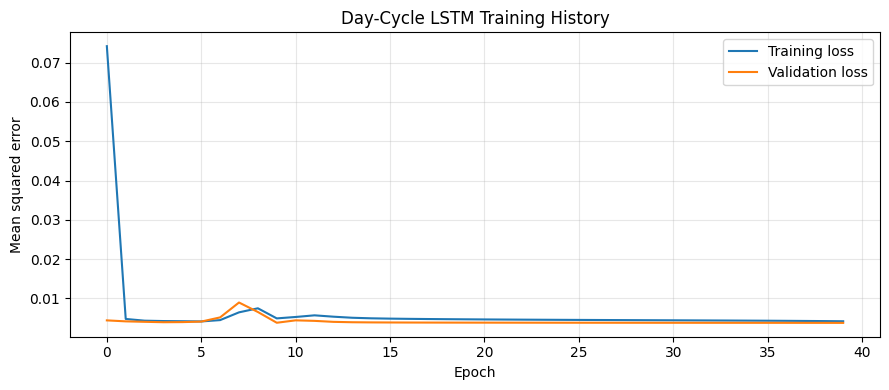

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(cycle_training_losses, label="Training loss")
plt.plot(cycle_validation_losses, label="Validation loss")
plt.title("Day-Cycle LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 24. Rolling one-step evaluation

First evaluate the model using actual historical temperatures in every test window. This measures ordinary one-step performance before recursive forecasting.

In [ ]:
cycle_model.eval()

with torch.no_grad():
    cycle_rolling_scaled = cycle_model(
        X_test_cycle_tensor
    ).numpy()

cycle_rolling_predictions = cycle_temperature_scaler.inverse_transform(
    cycle_rolling_scaled
).flatten()

actual_cycle_test_values = cycle_temperature_scaler.inverse_transform(
    y_test_cycle
).flatten()

cycle_rolling_mae = mean_absolute_error(
    actual_cycle_test_values,
    cycle_rolling_predictions
)

cycle_rolling_rmse = np.sqrt(
    mean_squared_error(
        actual_cycle_test_values,
        cycle_rolling_predictions
    )
)

print(f"Day-cycle rolling MAE:  {cycle_rolling_mae:.3f} °C")
print(f"Day-cycle rolling RMSE: {cycle_rolling_rmse:.3f} °C")

Day-cycle rolling MAE:  1.222 °C
Day-cycle rolling RMSE: 1.495 °C


## 25. Recursive forecast with known future day-cycle features

At each recursive step:

1. predict the next scaled temperature;
2. calculate sine and cosine from the known forecast date;
3. append all three values to the input window;
4. repeat.

The calendar signal remains correct even when earlier temperature predictions contain errors.

In [ ]:
def recursive_forecast_with_day_cycle(
    model,
    initial_window,
    future_dates,
    temperature_scaler
):
    """Generate recursive forecasts using known future calendar features."""

    model.eval()
    current_window = initial_window.copy()
    predictions_scaled = []

    with torch.no_grad():
        for forecast_date in pd.to_datetime(future_dates):
            input_tensor = torch.tensor(
                current_window,
                dtype=torch.float32
            ).unsqueeze(0)

            next_temperature_scaled = model(input_tensor).item()
            predictions_scaled.append(next_temperature_scaled)

            forecast_day = forecast_date.dayofyear
            next_day_sin = np.sin(
                2 * np.pi * forecast_day / 365.25
            )
            next_day_cos = np.cos(
                2 * np.pi * forecast_day / 365.25
            )

            next_feature_row = np.array([[
                next_temperature_scaled,
                next_day_sin,
                next_day_cos
            ]])

            current_window = np.vstack([
                current_window[1:],
                next_feature_row
            ])

    predictions_scaled = np.array(
        predictions_scaled
    ).reshape(-1, 1)

    return temperature_scaler.inverse_transform(
        predictions_scaled
    ).flatten()

In [ ]:
initial_cycle_window = cycle_features_all[
    validation_end - WINDOW_SIZE:validation_end
]

future_test_dates = df_cycle["date"].iloc[
    validation_end:
].reset_index(drop=True)

cycle_recursive_predictions = recursive_forecast_with_day_cycle(
    model=cycle_model,
    initial_window=initial_cycle_window,
    future_dates=future_test_dates,
    temperature_scaler=cycle_temperature_scaler
)

cycle_recursive_mae = mean_absolute_error(
    actual_cycle_test_values,
    cycle_recursive_predictions
)

cycle_recursive_rmse = np.sqrt(
    mean_squared_error(
        actual_cycle_test_values,
        cycle_recursive_predictions
    )
)

print(f"Day-cycle recursive MAE:  {cycle_recursive_mae:.3f} °C")
print(f"Day-cycle recursive RMSE: {cycle_recursive_rmse:.3f} °C")

Day-cycle recursive MAE:  1.265 °C
Day-cycle recursive RMSE: 1.539 °C


## 26. Compare all approaches

The day-cycle recursive model should usually follow the broad annual pattern better. Exact values can vary because neural-network training is stochastic.

In [ ]:
comparison_results = pd.DataFrame({
    "Approach": [
        "Persistence baseline",
        "Temperature-only rolling LSTM",
        "Temperature-only recursive LSTM",
        "Day-cycle rolling LSTM",
        "Day-cycle recursive LSTM"
    ],
    "MAE (°C)": [
        baseline_mae,
        lstm_mae,
        recursive_mae,
        cycle_rolling_mae,
        cycle_recursive_mae
    ],
    "RMSE (°C)": [
        baseline_rmse,
        lstm_rmse,
        recursive_rmse,
        cycle_rolling_rmse,
        cycle_recursive_rmse
    ]
})

comparison_results.round(3)

,Approach,MAE (°C),RMSE (°C)
0,Persistence baseline,1.592,1.944
1,Temperature-only rolling LSTM,1.239,1.585
2,Temperature-only recursive LSTM,6.575,7.927
3,Day-cycle rolling LSTM,1.222,1.495
4,Day-cycle recursive LSTM,1.265,1.539


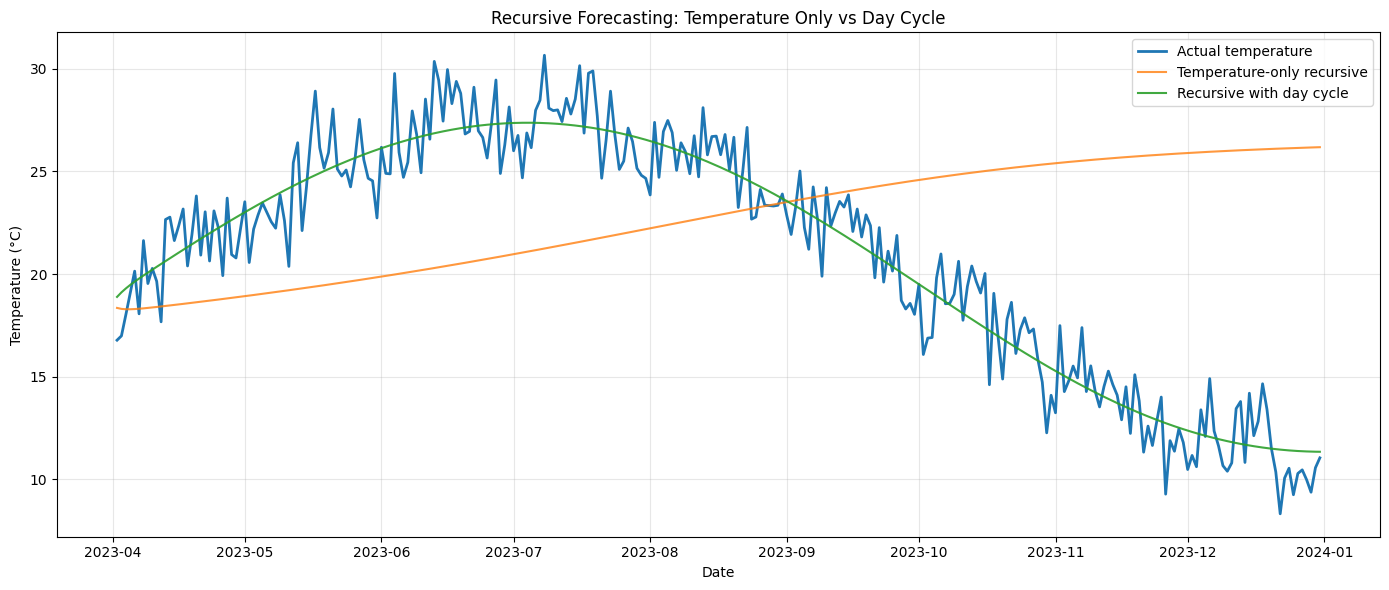

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    future_test_dates,
    actual_cycle_test_values,
    label="Actual temperature",
    linewidth=2
)

plt.plot(
    future_test_dates,
    recursive_predictions,
    label="Temperature-only recursive",
    alpha=0.8
)

plt.plot(
    future_test_dates,
    cycle_recursive_predictions,
    label="Recursive with day cycle",
    alpha=0.9
)

plt.title("Recursive Forecasting: Temperature Only vs Day Cycle")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 27. Why the extra information helps

The temperature-only recursive model must infer the season entirely from its recent temperature window. Once errors accumulate, that window can become unrealistic.

The day-cycle model receives two reliable known future covariates:

- `day_sin` describes progression around the annual cycle;
- `day_cos` distinguishes positions that have similar sine values.

Calendar features guide the broad seasonal pattern, but they cannot predict random weather fluctuations. Long recursive forecasts may therefore still look smoother than actual observations.